### IMPORTING OR UPLOADING AN IMAGE

##### 1. USING MATPLOTLIB

In [2]:
import matplotlib.pyplot as plt

In [3]:
image = plt.imread("Photo.jpg")
#Note that plt.imread() loads image as numpy array

In [4]:
#Check the shape of the image
print(image.shape)

(3508, 2552, 3)


The result returns (Height, width, channel). The channel can either be 1 or 3. 

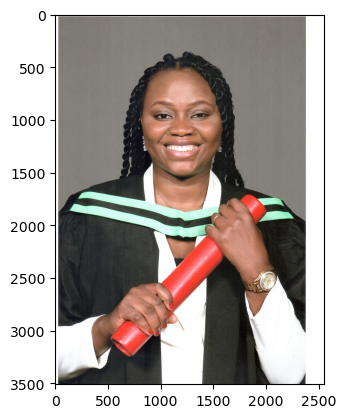

In [5]:
#Show the image
plt.imshow(image)
plt.show()

In [6]:
#Access the pixels of the image
print(image)

[[[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 ...

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [253 253 253]
  [252 252 252]
  [252 252 252]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [253 253 253]
  [252 252 252]
  [252 252 252]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [253 253 253]
  [252 252 252]
  [251 251 251]]]


Each pixel has three values representing three channels. For example [255, 255, 255] means the pixel has Red = 255, Green = 255, Blue = 255

In [7]:
#Convert the image to Numpy Array
import numpy as np

In [8]:
image_array = np.array(image)

In [9]:
#Get the shape
print(image_array.shape)

(3508, 2552, 3)


##### Load Single Image Using Tensorflow

In [10]:
from tensorflow.keras.utils import load_img

In [11]:
image_tensor = load_img("Photo.jpg")

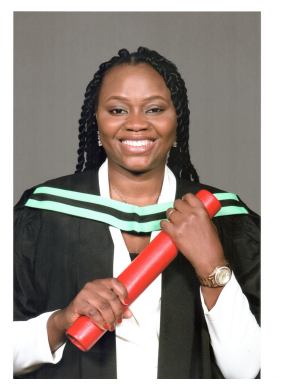

In [12]:
#Display the image
plt.imshow(image_tensor)
plt.axis("off")
plt.show()

The image is a PIL image object and not yet a numpy array

In [13]:
print(type(image_tensor))

<class 'PIL.JpegImagePlugin.JpegImageFile'>


##### Convert Image to Numpy Array

This can be done using np.array() OR img_to_array()

In [14]:
imageArray1 = np.array(image_tensor)

In [15]:
print(imageArray1)

[[[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 ...

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [253 253 253]
  [252 252 252]
  [252 252 252]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [253 253 253]
  [252 252 252]
  [252 252 252]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [253 253 253]
  [252 252 252]
  [251 251 251]]]


In [16]:
#An alternative approach
from tensorflow.keras.utils import img_to_array

In [17]:
#img_to_array returns float array and may affect the output of plt.imshow()
#To get the correct photo, normalize first then plt.imshow()
imageArray2 = img_to_array(image_tensor)

In [18]:
print(type(imageArray1))

<class 'numpy.ndarray'>


In [19]:
print(type(imageArray2))

<class 'numpy.ndarray'>


In [20]:
#Print the first pixel
print(imageArray2[0, 0])

[255. 255. 255.]


##### Resize Image

In [21]:
#RESIZE THE IMAGE WHEN LOADING
#image = load_img("Photo.jpg", target_size = (244, 244))
#(height, weight)

For images loaded with plt.imread(), they return python array and therefore you can use the following approach to resize

In [22]:
from skimage.transform import resize

In [23]:
image_size = (244, 244)
new_image = resize(imageArray2, image_size)

In [24]:
print(new_image.shape)

(244, 244, 3)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


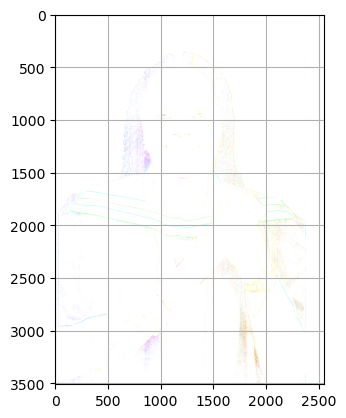

In [25]:
plt.imshow(imageArray2)
plt.grid()
plt.show()

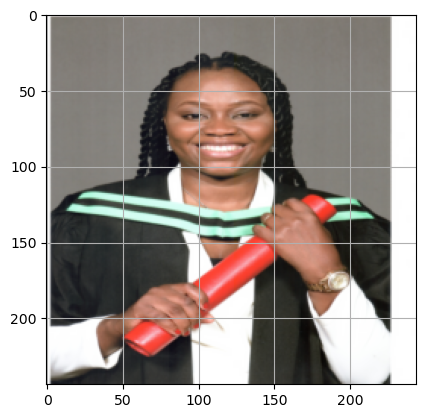

In [26]:
image_size1 = (244, 244)
new_image1 = resize(imageArray1, image_size)

plt.imshow(new_image1)
plt.grid()
plt.show()

##### Normalize

In [27]:
new_image = new_image / 255.0

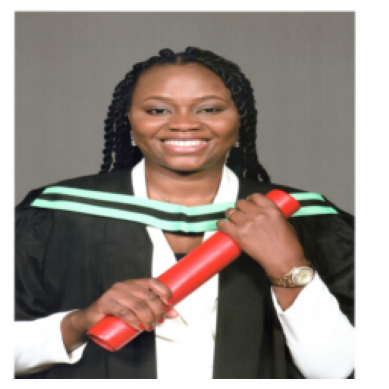

In [28]:
#After normalization, we can try to show the image again

plt.imshow(new_image)
plt.axis("off")
plt.show()

##### Add Batch Dimension

Originally, the image is represented as (height, weight, channel). However, CNN (Tensorflow) usually expect a batch of images such as (batch_size, height, width, channels). So even if we have only one image, you can create a batch containing only one image (1, height, width, channel)

In [29]:
new_image = np.expand_dims(new_image, axis=0)
print(new_image.shape)

(1, 244, 244, 3)


### LOADING AN ENTIRE DATASET FROM FOLDERS

1. Start by downloading the pictures of cats and dogs
2. Separate them into two different folders - cats and dogs respectively
3. Put the two folders in a folder called dataset

In [30]:
from  tensorflow.keras.utils import image_dataset_from_directory

In [31]:
#batch_size = 32 means thee data will be loaded and processed 
#in groups of 32 images at a time rather than loading the entire image at once.  

images = image_dataset_from_directory(
    "dataset",
    image_size = (224, 224),
    batch_size = 32
)

Found 12 files belonging to 2 classes.


The above code does the following:

1. Loads the images
2. resizes the images
3. creates label for each image based on the folder name
4. groups images into batches

##### 1. Check the Class Names

In [32]:
print(images.class_names)

['Cats', 'Dogs']


##### 2. Get the Shape of Images

In [33]:
for image, label in images.take(1): #Take first batch
    print(image.shape) #returns batch shape not individual image shape
    print(label.shape)
    print(image.dtype)
    print(label.dtype)

(12, 224, 224, 3)
(12,)
<dtype: 'float32'>
<dtype: 'int32'>


##### 3. Get individual Image Shape

In [34]:
for image, label in images.take(1):
    print(image[0].shape)
    print(image[0].dtype)

(224, 224, 3)
<dtype: 'float32'>


##### 4. Count the Total Number of Images

In [35]:
#Total images = batches size * no of batches
No_of_batches = len(images)
batch_size = 11
total_images = No_of_batches * batch_size

##### 5. Display one Image

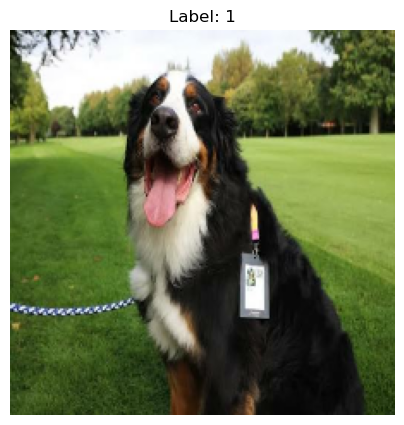

In [36]:
for image, label in images.take(1):
    image_1 = image[0]
    label_1 = label[0]

    plt.figure(figsize=(5, 5))

    if image_1.numpy().max() > 1.0:
        plt.imshow(image_1/255.0)
    else:
        plt.imshow(image_1)
    
    plt.title(f"Label: {label_1}")
    plt.axis("off")
    plt.show()

##### 6. Display Images with Class Names

In [37]:
def show_with_class_names(dataset):
    
    class_names = images.class_names

    for image, label in images.take(1):

        fig, axes = plt.subplots(3, 3, figsize=(10, 10))
        axes = axes.flatten()

        #We want to show the first nine images
        for i in range(9):
            img = image[i]
            label_id = int(label[i].numpy())
            label_name = class_names[label_id]

            #Convert values to numpy array
            if img.numpy().max() > 1.0:
                img = img / 255.0

            #Display the image
            axes[i].imshow(img)
            axes[i].set_title(
                f"Class: {label_name}\n" 
                f"(ID: {label_id})\n"
                f"(Min: {img.numpy().min():.3f} Max: {img.numpy().max():.3f})")
            axes[i].axis("off")

        plt.tight_layout()
        plt.show()
        break          

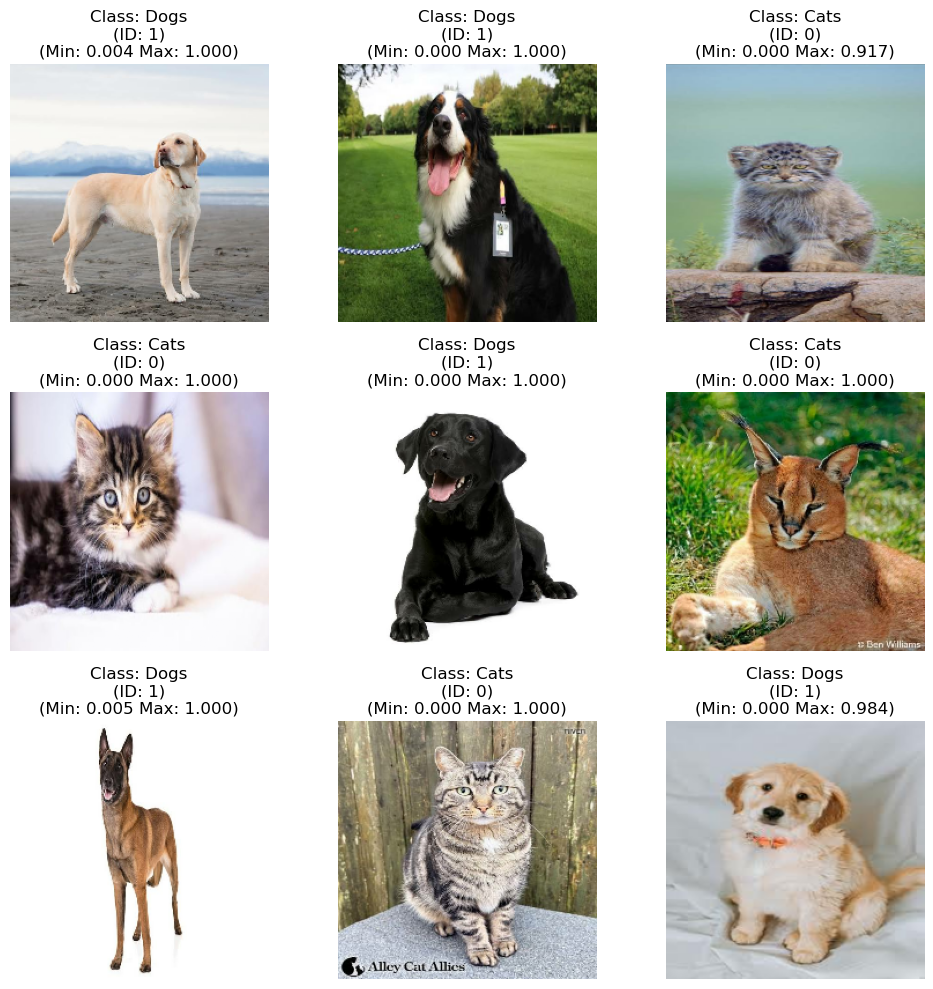

In [38]:
show_with_class_names(images)

### POSSIBLE PROBLEMS AND SOLUTIONS

##### 1. When Images Display too Bright or Too Faint

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


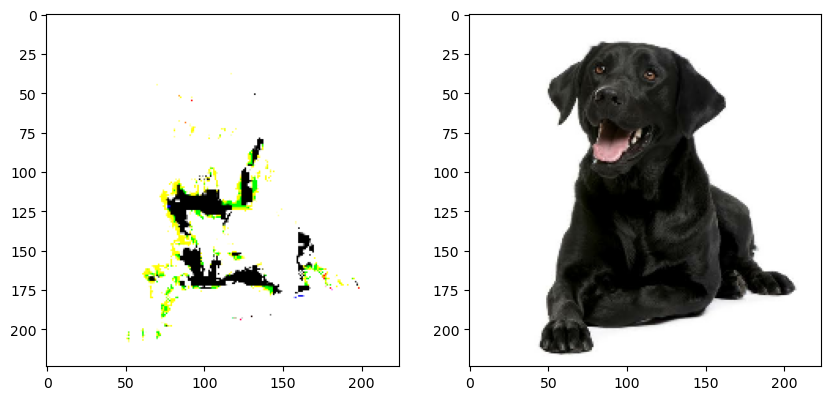

In [39]:
# Problem: Values in [0, 255] displayed as floats
for image, label in images.take(1):
    
    img = image[0]

    fig, axes = plt.subplots(1, 2, figsize=(10, 10))
    axes = axes.flatten()
    # This shows faint/washed-out image
    axes[0].imshow(img)  # ❌ Faint display
    
    #Solution 1: Divide by 255
    axes[1].imshow(img / 255.0)  # ✅ Correct display

##### 2. Images are Standardized (Negative Values)

Min: 0.0, Max: 233.8831024169922


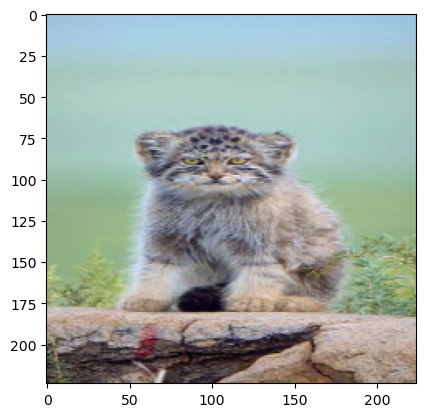

In [40]:
# Problem: Images have negative values (standardized)
for image, label in images.take(1):
    img = image[0]
    print(f"Min: {img.numpy().min()}, Max: {img.numpy().max()}")  # [-0.5, 0.5] or similar
    
    # Solution: Normalize to [0, 1]
    img_normalized = (img - img.numpy().min()) / (img.numpy().max() - img.numpy().min())
    plt.imshow(img_normalized)

#### Convert Entire Image Dataset to Array

In order to convert the tensorflow dataset into array, we need to extract the images from the batches one after another and then combine the images.

In [41]:
all_images = []
all_labels = []

for image_batch, label_batch in images:

    all_images.append(image_batch.numpy())
    all_labels.append(label_batch.numpy())

imagesArray = np.concatenate(all_images, axis = 0)
labelsArray = np.concatenate(all_labels, axis = 0)

In [42]:
#Find the shape
print(imagesArray.shape)
print(labelsArray.shape)

(12, 224, 224, 3)
(12,)


In [43]:
#Print the first image and label
print(labelsArray[0])
print(imagesArray[0])

0
[[[ 36.633926  46.294643  47.792408]
  [ 36.633926  46.294643  47.792408]
  [ 36.633926  46.294643  47.792408]
  ...
  [ 34.13616   46.294643  46.95982 ]
  [ 34.13616   46.294643  46.95982 ]
  [ 34.13616   46.294643  46.95982 ]]

 [[149.       177.9866   194.96875 ]
  [149.       177.9866   194.96875 ]
  [149.       177.9866   194.96875 ]
  ...
  [146.00447  177.48885  193.47098 ]
  [146.00447  177.48885  193.47098 ]
  [146.00447  177.48885  193.47098 ]]

 [[142.51115  182.51115  208.14082 ]
  [142.51115  182.51115  208.13335 ]
  [142.51115  182.51115  207.71109 ]
  ...
  [139.51115  181.51115  205.71107 ]
  [139.51115  181.51115  206.13333 ]
  [139.51115  181.51115  206.14082 ]]

 ...

 [[ 57.770393  47.09632   50.933357]
  [ 66.92483   56.872925  58.60118 ]
  [ 65.938446  56.264378  54.86257 ]
  ...
  [161.22427  146.89835  133.89835 ]
  [155.99197  141.66605  130.34012 ]
  [149.45175  135.12582  123.799904]]

 [[ 47.46794   44.09787   46.9768  ]
  [ 57.93099   54.935383  55.195347

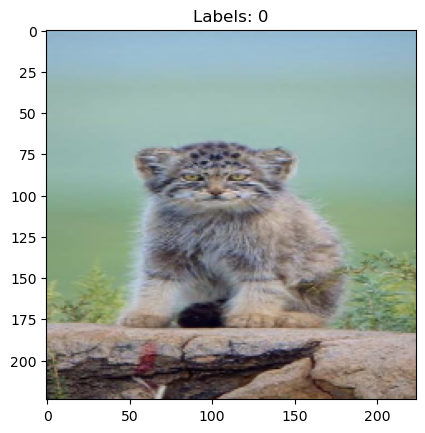

In [44]:
#Display the image
plt.imshow(imagesArray[0] / 255.0)
plt.title(f"Labels: {labelsArray[0]}")
plt.show()

#### Export all images from the numpy array as files

In [45]:
import os

#Create an output folder
output_folder = "exported_image_test"

os.makedirs(output_folder, exist_ok = True)

#Loop through all images
for i, image in enumerate(imagesArray):

    #convert to uint8 if necessary
    #Converts the floating point pixel values to int
    image = image.astype("uint8")

    #Create file name
    filename = os.path.join(
        output_folder, f"image_{i}.jpg")

    #Save the image
    plt.imsave(filename, image)

print(f"{len(imagesArray)} images exported successfully")

12 images exported successfully


#### Export Images with Class Labels

In [46]:
#Note the use of images dataset
class_names = images.class_names

folder_name = "exported_images_withlabels"

os.makedirs(folder_name, exist_ok = True)

for i, image in enumerate(imagesArray):

    label = labelsArray[i] #Get label number for this image
    
    #Convert label to class name
    class_name = class_names[label]

    #Creates the path
    class_folder = os.path.join(folder_name, class_name)

    #Physically creates the folder
    os.makedirs(class_folder, exist_ok = True)

    #Convert image to uint8
    image = image.astype("uint8")

    #Save image
    filename = os.path.join(class_folder, f"image_{i}.jpg")

    plt.imsave(filename, image)

print("All images exported successfully")

All images exported successfully


### Load Saved(exported) Images 

In [47]:
import tensorflow as tf

folder_name = "exported_images_withlabels"

images = tf.keras.utils.image_dataset_from_directory(
    folder_name,
    image_size = (224, 224),
    batch_size = 32,
    shuffle=True #Images randomly shuffled before presented to CNN
)

Found 12 files belonging to 2 classes.


### Confirm that images are loaded correctly

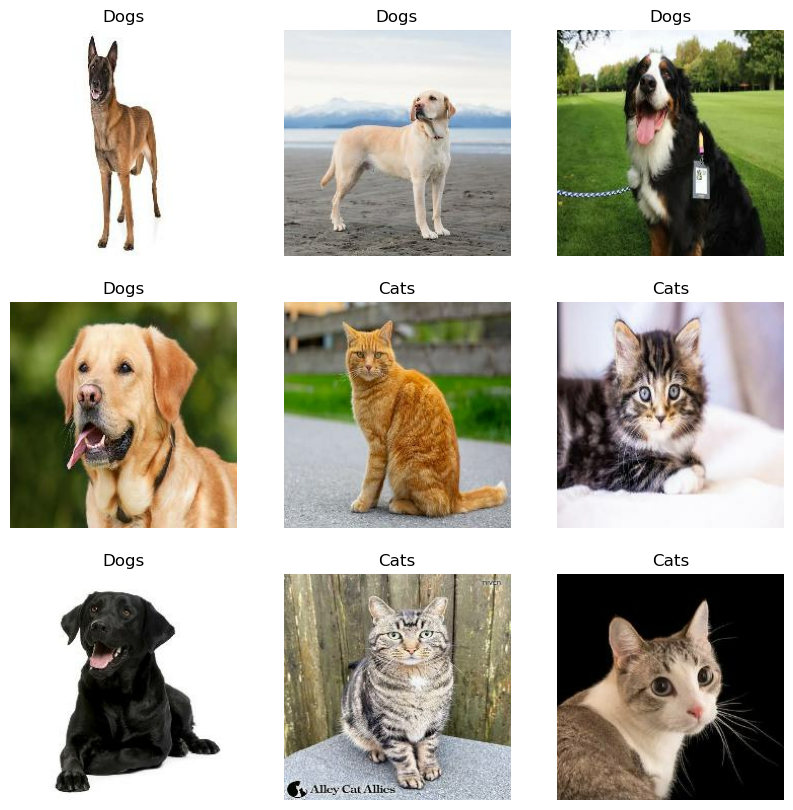

In [48]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

for image_batch, label_batch in images.take(1):

    for i in range(9):

        plt.subplot(3, 3, i + 1)

        plt.imshow(image_batch[i].numpy().astype("uint8"))

        plt.title(class_names[label_batch[i]])
        plt.axis("off")

plt.show()

### Augmenting Images

Image augmentation is the process of creating variations of existing training images by applying transformations such as rotation, flipping, zooming, cropping etc. The goal is not to create new information but to make the CNN see slightly different versions of the same underlying objects

Instead of creating new image files, augmentation applies transformation to existing training images, so that the CNN can see slightly different versions of the same file. This can help the model generalize better and reduce overfitting. 

If images is a TensorFlow dataset created using something such as:

tf.keras.utils.image_dataset_from_directory()

each element of the dataset normally contains

(image batch, label batch)

In [49]:
import tensorflow as tf

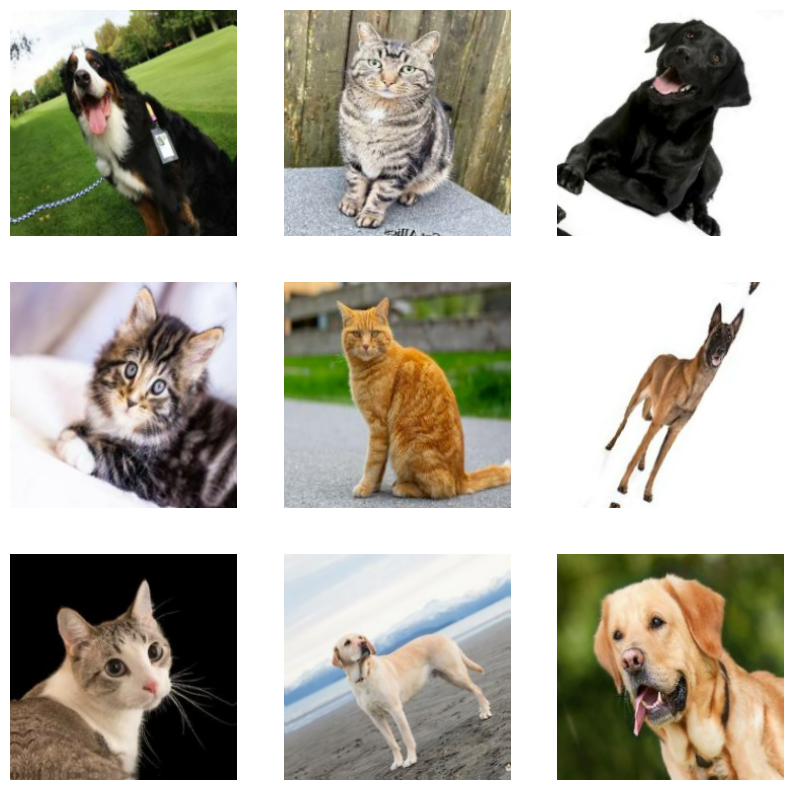

In [50]:
# Create the augmentation pipeline
# keras.Sequential creates a sequence of layers
# that will be applied one after another.
# The pipeline contains three augmentation operations
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1), #0.1 * 360 = 36 degrees
    tf.keras.layers.RandomZoom(0.1)
])

#.take(1) means take a batch from the dataset. 
for image, label in images.take(1):

    plt.figure(figsize=(10, 10))

    for i in range(9):

        augmented_image = data_augmentation(
            image[i:i+1], #This is to retain the batch dimension(structure)
            training=True
        )

        plt.subplot(3, 3, i + 1)
        plt.imshow(
            augmented_image[0].numpy().astype("uint8")
        )
        plt.axis("off")

    plt.show()

### Generate and Save the Augmented Images

We will save this into a new folder

In [51]:
#Determines the number of augmentation versions
num_augmentations = 3 

#Initializes a counter to track and assign
#unique identifiers to each processed image
image_number = 0

#Get the class names
class_names = images.class_names

#Create output directory
output_directory = "augmented_dataset"
os.makedirs(output_directory, exist_ok = True)

for image, label in images:

    #Go through each image in the batch
    for i in range(len(image)):

        #Get an image
        image_1 = image[i]

        #Get its label
        label_1 = label[i].numpy()

        #Convert numerical label to class name
        class_name = class_names[label_1]

        #Create appropriate class folders
        class_folder = os.path.join(output_directory, class_name)
        os.makedirs(class_folder, exist_ok = True)

        #Save original image

        original_image = image_1.numpy().astype("uint8")

        original_filename = os.path.join(
            class_folder, f"image_{image_number}.jpg")

        plt.imsave(original_filename, original_image)

        #Create augmented versions
        for j in range(num_augmentations):

            #Add batch dimension
            image_batch = tf.expand_dims(image_1, axis = 0)

            #Apply random augmentation
            augmented_image = data_augmentation(image_batch, training=True)

            #Remove Batch Dimension
            augmented_image = augmented_image[0]

            #Convert tensor to numpy array
            augmented_image = augmented_image.numpy()

            # Ensure valid pixel values
            augmented_image = (
                augmented_image
                .clip(0, 255)
                .astype("uint8")
            )

            # Create filename
            augmented_filename = os.path.join(
                class_folder,
                f"image_{image_number}_aug_{j+1}.jpg"
            )

            # Save augmented image
            plt.imsave(
                augmented_filename,
                augmented_image
            )

            image_number += 1

print("Augmentation completed successfully.")

Augmentation completed successfully.


## Using larger dataset

#### 1. Load the dataset

In [52]:
#We are using a new dataset
folder_name = "PetImages"

petImages = tf.keras.utils.image_dataset_from_directory(
    folder_name,
    image_size = (224, 224),
    batch_size = 32,
    shuffle=True, #Images randomly shuffled before presented to CNN
    seed = 42
)

Found 24998 files belonging to 2 classes.


In [53]:
pet_class_name = petImages.class_names
print(pet_class_name)

['Cat', 'Dog']


#### 2. View Part of the dataset

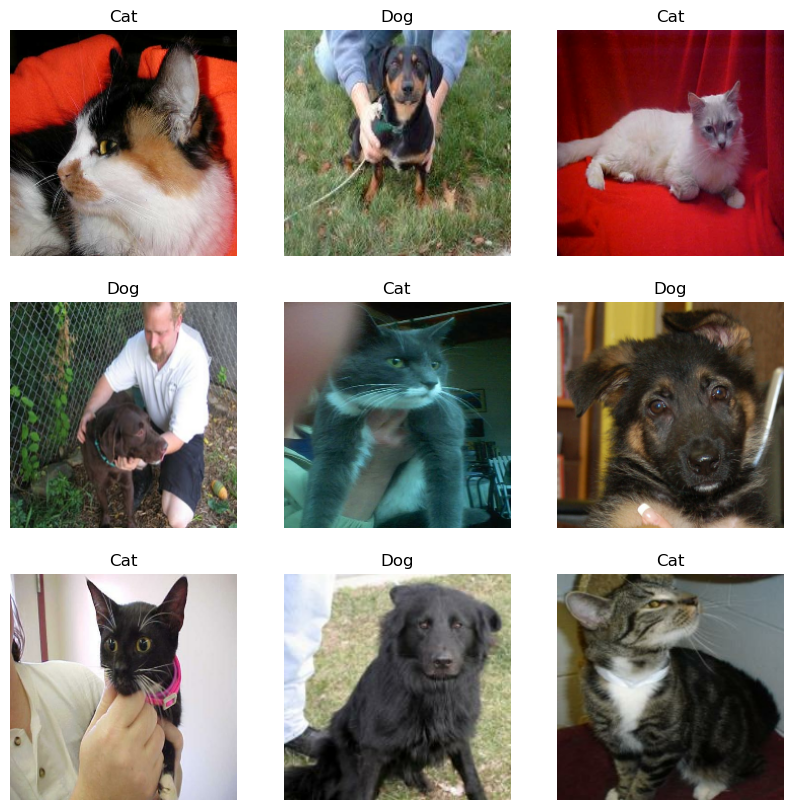

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

for image_batch, label_batch in petImages.take(1):

    for i in range(9):

        plt.subplot(3, 3, i + 1)

        plt.imshow(image_batch[i].numpy().astype("uint8"))

        plt.title(pet_class_name[label_batch[i]])
        plt.axis("off")

plt.show()

#### 3. Split Dataset

Because we used the "image_dataset_from_directory", that is, the tensorflow tf.data.Dataset API, the approach to data splitting will be different. The key difference is that train_test_split() is designed primarily for arrays/dataframes, whereas take() and skip() operate directly on a TensorFlow dataset pipeline.

In [55]:
#data size returns the number of batches, not the number of images
dataset_size = tf.data.experimental.cardinality(petImages).numpy()

#Allocate 80% to training
train_size = int(0.8 * dataset_size)
#Allocate 10% to validation
val_size = int(0.1 * dataset_size)

#Takes the first 80% of the batches
train_ds = petImages.take(train_size)
#Skips the training and returns the remaining 20%
remaining_ds = petImages.skip(train_size)

val_ds = remaining_ds.take(val_size)

test_ds = remaining_ds.skip(val_size)

#### 4. Augmentation

Note that the augmentation below is not stored in a folder but kept in the memory

In [56]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

#### 5. Normalization

Your images currently have pixel values approximately between 0 and 255. CNN trains more effectively when these are scaled to 0 - 1. 

In [57]:
normalization = tf.keras.layers.Rescaling(1./255)

#### 6. Build your CNN

In [58]:
tf.keras.Sequential
tf.keras.layers.Rescaling
tf.keras.layers.Conv2D
tf.keras.layers.MaxPooling2D
tf.keras.layers.Flatten
tf.keras.layers.Dense

keras.src.layers.core.dense.Dense

In [59]:
model = tf.keras.Sequential([

    # Data augmentation
    data_augmentation,

    # Normalize pixels
    tf.keras.layers.Rescaling(1./255),

    # First convolution block
    tf.keras.layers.Conv2D(
        32, #Number of filters
        (3, 3), #Filter size
        activation="relu"
    ),

    tf.keras.layers.MaxPooling2D(),

    # Second convolution block
    tf.keras.layers.Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),

    tf.keras.layers.MaxPooling2D(),

    # Third convolution block
    tf.keras.layers.Conv2D(
        128,
        (3, 3),
        activation="relu"
    ),

    tf.keras.layers.MaxPooling2D(),

    # Convert feature maps into vector
    tf.keras.layers.Flatten(),

    # Fully connected layer
    tf.keras.layers.Dense(
        128,
        activation="relu"
    ),

    # Binary classification
    tf.keras.layers.Dense(
        1,
        activation="sigmoid"
    )
])

#### 7. Compile

In [60]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [61]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=2
)

Epoch 1/2
 21/625 ━━━━━━━━━━━━━━━━━━━━ 9:17 923ms/step - accuracy: 0.5166 - loss: 1.0686

InvalidArgumentError: Graph execution error:

Detected at node decode_image/DecodeImage defined at (most recent call last):
<stack traces unavailable>
Input size should match (header_size + row_size * abs_height) but they differ by 2
	 [[{{node decode_image/DecodeImage}}]]
	 [[IteratorGetNext]] [Op:__inference_multi_step_on_iterator_13743]